# Release region

## Salinity of the ARP

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.geometry import Polygon, box as sbox
from shapely.ops import unary_union
from matplotlib.path import Path as MplPath

In [2]:
# --- GLORYS12 / NEMO mesh ---
pathUVW = '/work/bk1450/b383184/Amazon/Mercator/data/variables/'
Hgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc'
Zgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc'
# sal     = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/tracers/S_*'

# map window, reused everywhere
EXTENT = [-52, -46, -3, 4]

In [3]:
ss = xr.open_dataset('Sal_m_0_7m.nc').compute()
ss

<xarray.Dataset> Size: 1GB
Dimensions:  (lat: 499, lon: 1260, time: 264)
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917
  * time     (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2014-12-01
Data variables:
    sal      (time, lat, lon) float64 1GB 35.74 35.74 35.74 ... nan nan nan

In [4]:
uv = xr.open_dataset('UV_0_7m.nc').compute()
uv

<xarray.Dataset> Size: 20GB
Dimensions:  (time: 7973, lat: 499, lon: 1260)
Coordinates:
  * time     (time) datetime64[ns] 64kB 1993-01-01T12:00:00 ... 2014-12-31T12...
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917
Data variables:
    UV       (time, lat, lon) float32 20GB nan nan nan nan ... nan nan nan nan

In [21]:
uv5 = uv.UV.resample(time='1Y').mean()
# uv5

/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/groupers.py:513: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  self.index_grouper = pd.Grouper(


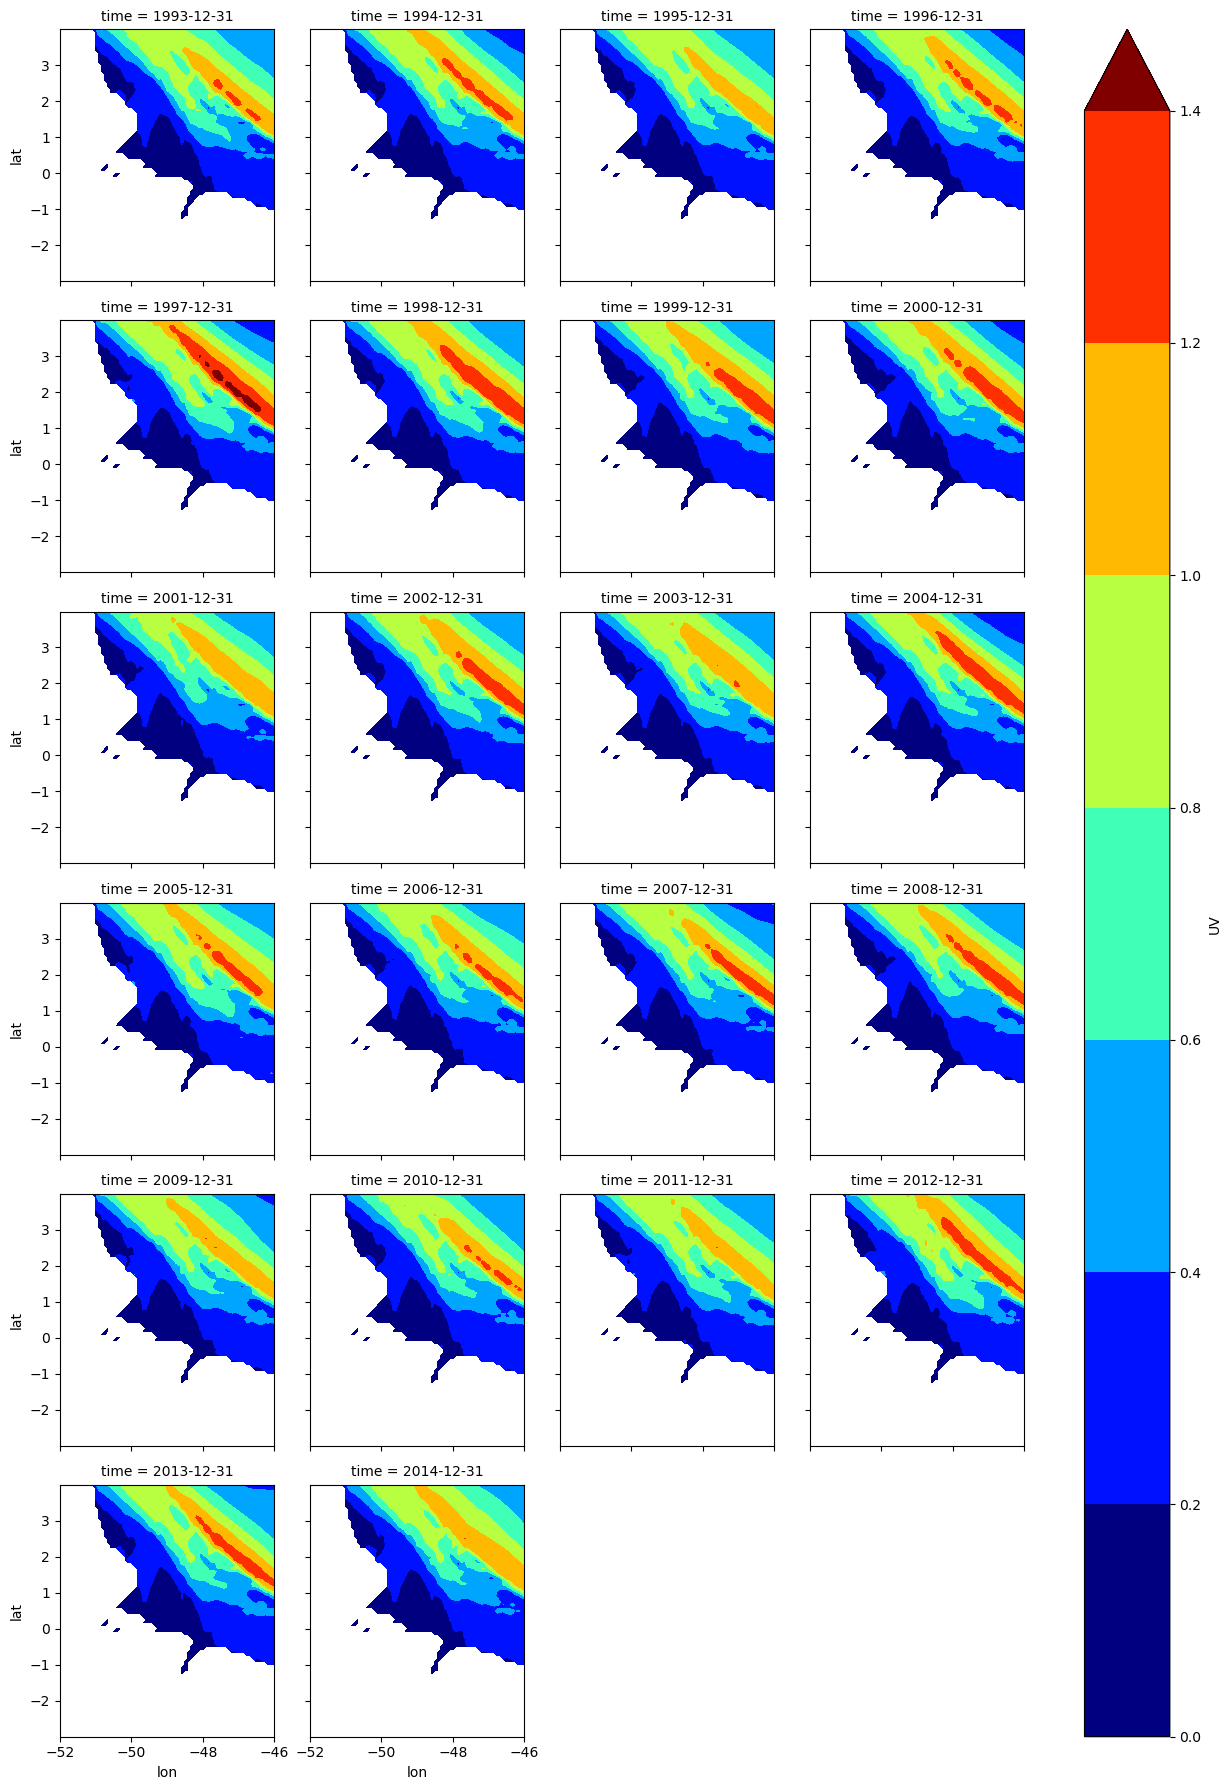

In [22]:
uv5.sel(lon=slice(-52,-46),lat=slice(-3,4)).\
    plot.contourf(x='lon',y='lat',col='time',col_wrap=4,robust=True,cmap='jet')


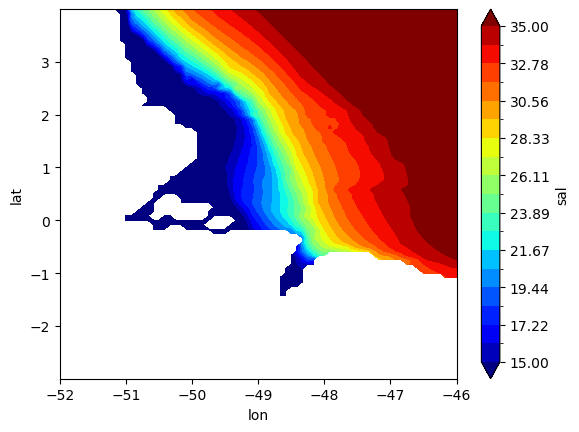

In [9]:
ss.sal.mean(dim='time').sel(lon=slice(-52,-46),lat=slice(-3,4)).plot.contourf(robust=True,cmap='jet',levels=19,vmin=15,vmax=35)
# EXTENT = [-52, -46, -3, 4]

In [19]:
s5 = ss.resample(time='1Y').mean()
s5

/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/groupers.py:513: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  self.index_grouper = pd.Grouper(


<xarray.Dataset> Size: 111MB
Dimensions:  (time: 22, lat: 499, lon: 1260)
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917
  * time     (time) datetime64[ns] 176B 1993-12-31 1994-12-31 ... 2014-12-31
Data variables:
    sal      (time, lat, lon) float64 111MB 35.6 35.6 35.6 35.6 ... nan nan nan

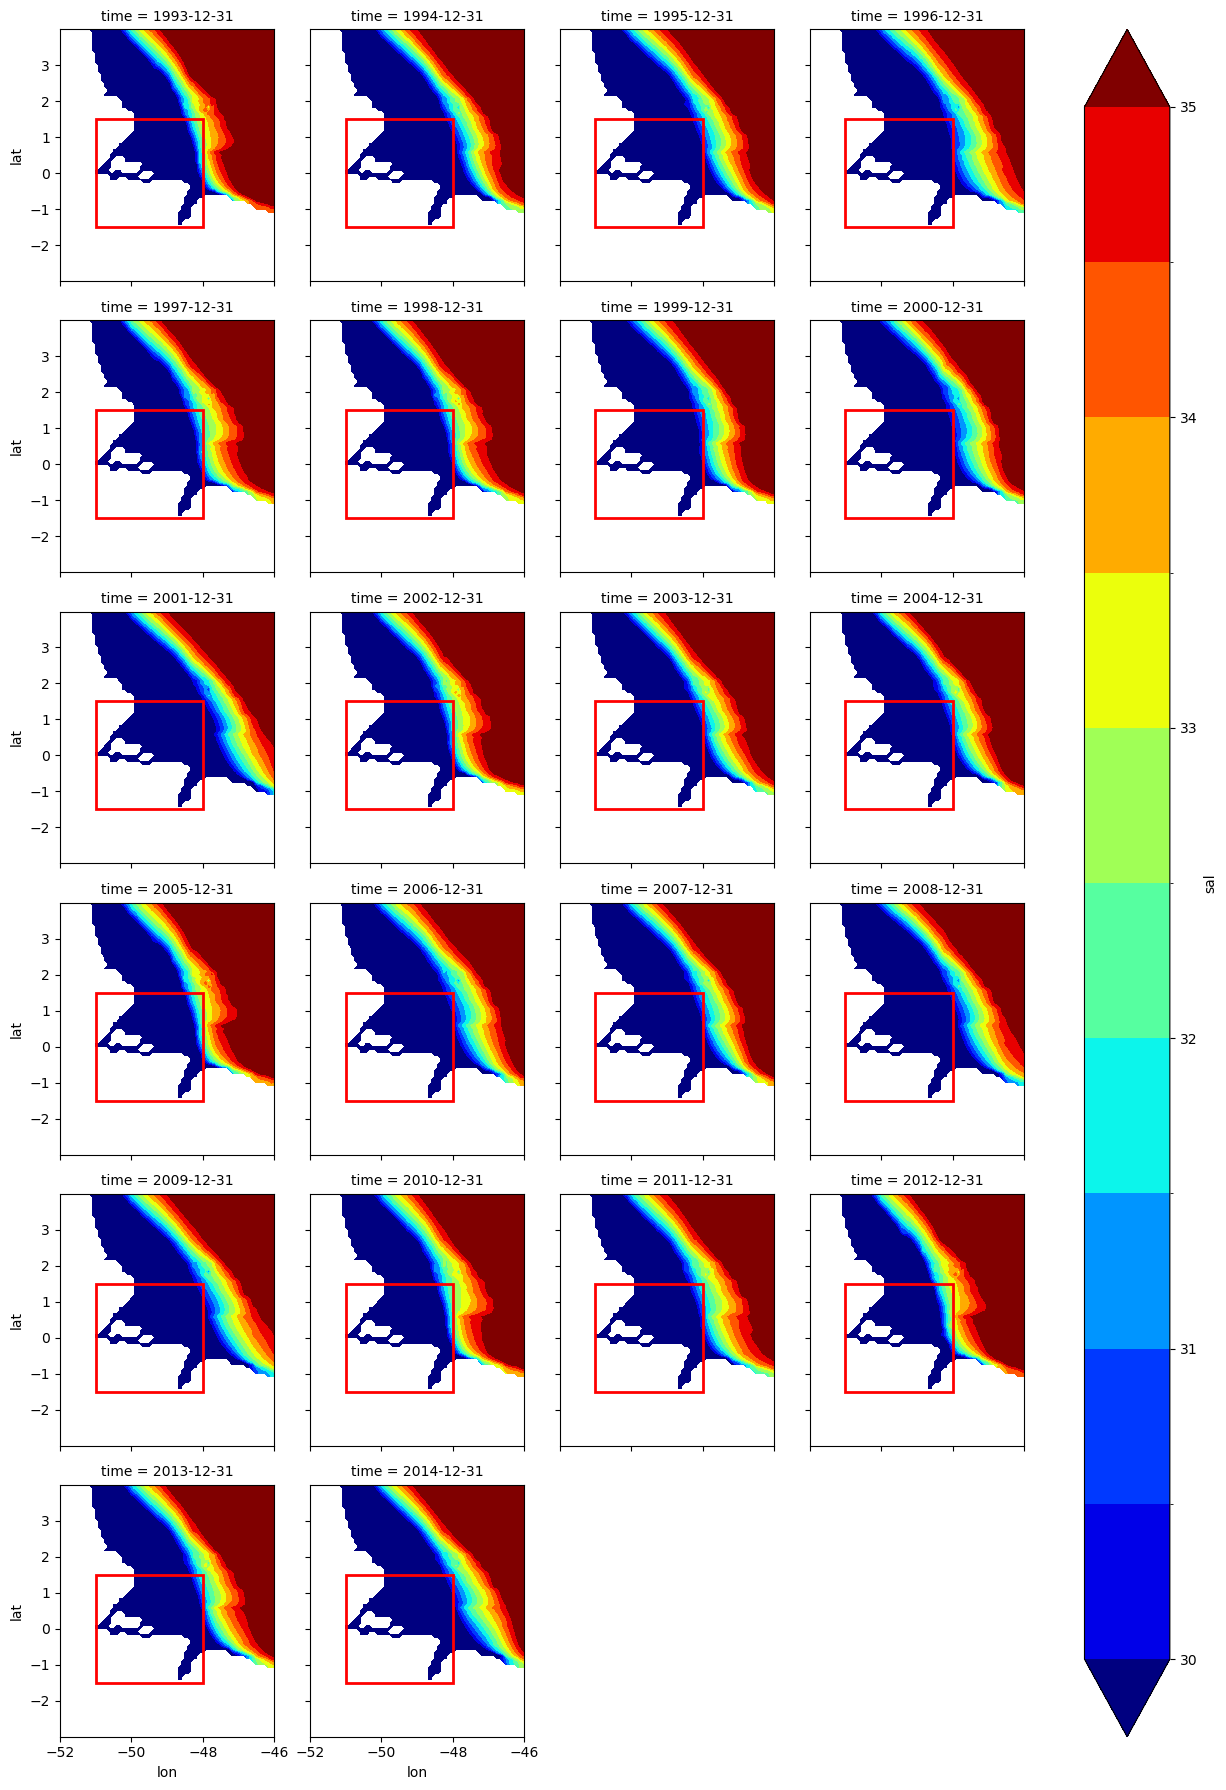

In [66]:
g = s5.sel(lon=slice(-52,-46),lat=slice(-3,4)).sal.\
    plot.contourf(x='lon',y='lat',col='time',col_wrap=4,
                 cmap='jet',levels=11,vmin=30,vmax=35)

# Loop over all axes and add the rectangle
for ax in g.axs.flat:
    # ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25])

    rect = patches.Rectangle((-51, -1.5), 3, 3, 
                             linewidth=2, edgecolor='r', facecolor='none')
    ax.add_patch(rect)


In [25]:
sali = ss.sal.mean(dim='time')
sali

<xarray.DataArray 'sal' (lat: 499, lon: 1260)> Size: 5MB
array([[35.42579823, 35.4273291 , 35.42898722, ..., 36.03820418,
        36.02407008, 36.00899412],
       [35.41510676, 35.41701962, 35.41893579, ..., 36.02680748,
        36.01146367, 35.99568309],
       [35.40406184, 35.4063822 , 35.40859782, ..., 36.01396891,
        35.99813105, 35.98241748],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan]], shape=(499, 1260))
Coordinates:
  * lat      (lat) float32 2kB -9.95 -9.868 -9.785 -9.703 ... 29.77 29.84 29.91
  * lon      (lon) float32 5kB -95.0 -94.92 -94.83 -94.75 ... 9.75 9.833 9.917

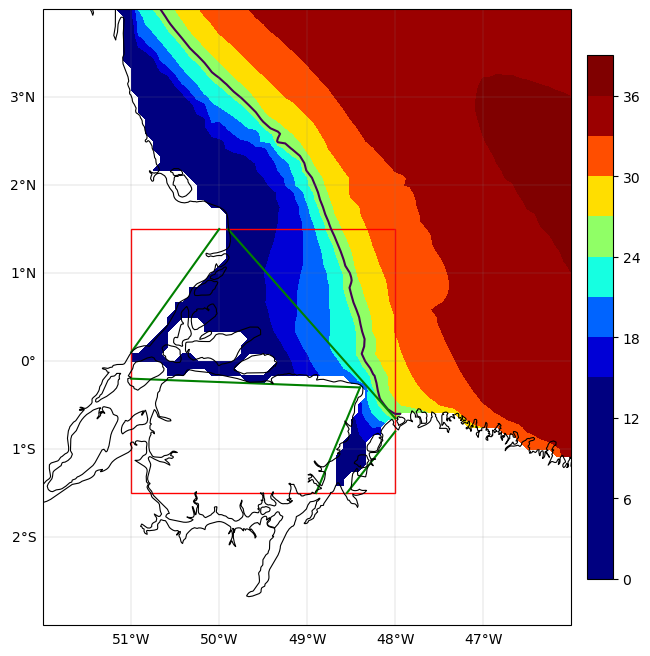

In [102]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

pc = ax.contourf(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),
                   cmap='jet',levels=11,vmin=15,vmax=35)

ax.contour(sali.lon, sali.lat, sali.data, transform=ccrs.PlateCarree(),levels=[25])

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  )

rect = patches.Rectangle((-51, -1.5), 3, 3, linewidth=1, edgecolor='r', facecolor='none')

# Add the patch to the Axes
ax.add_patch(rect)
ax.plot([-48,-49.9],[-0.65,1.5],color='g')
ax.plot([-51,-48.4],[-0.2,-0.30],color='g')
ax.plot([-50,-51],[1.5,0.1],color='g')
ax.plot([-48.9,-48.4],[-1.5,-0.30],color='g')
ax.plot([-48,-48.55],[-0.8,-1.5],color='g')
# levels=11,vmax=35,vmin=30


## Now the Plotting

In [39]:
# --- NEW: green release band ---
#   A  Amazon coast  - start of the old release line
#   B  Para coast    - old line prolonged SE until it strikes the Para bank
#   B' seaward corner off B  (pushed NE, not perpendicular: the Maranhao coast
#                             bends east, so a perpendicular corner runs aground)
#   A' seaward corner off A  (0.8 deg perpendicular)
green_lons = [-49.916, -48.392, -47.8, -49.250, -49.916]
green_lats = [  1.166,  -1.05,  -0.6,   1.610,    1.166]

## Bathymetry from GLORYS12v1

In [40]:
hgr = xr.open_dataset(Hgr)
zgr = xr.open_dataset(Zgr)

lon2d = hgr['glamt'].isel(t=0).values          # T-point longitudes (y, x)
lat2d = hgr['gphit'].isel(t=0).values          # T-point latitudes  (y, x)
mbathy = zgr['mbathy'].isel(t=0).values        # wet-level count, 0 = land
deptht = zgr['deptht'].isel(t=0).values        # bottom depth at T points [m]

# --- clip to the map window -------------------------------------------------
pad = 0.5
inbox = ((lon2d >= EXTENT[0] - pad) & (lon2d <= EXTENT[1] + pad) &
         (lat2d >= EXTENT[2] - pad) & (lat2d <= EXTENT[3] + pad))
yi, xi = np.where(inbox)
ys, ye = yi.min(), yi.max() + 1
xs, xe = xi.min(), xi.max() + 1
sl = (slice(ys, ye), slice(xs, xe))

lon_s, lat_s = lon2d[sl], lat2d[sl]
mb_s, dp_s   = mbathy[sl], deptht[sl]

# --- model bathymetry: masked on land ---------------------------------------
land_mask = (mb_s == 0)
bathy = np.where(land_mask, np.nan, dp_s)

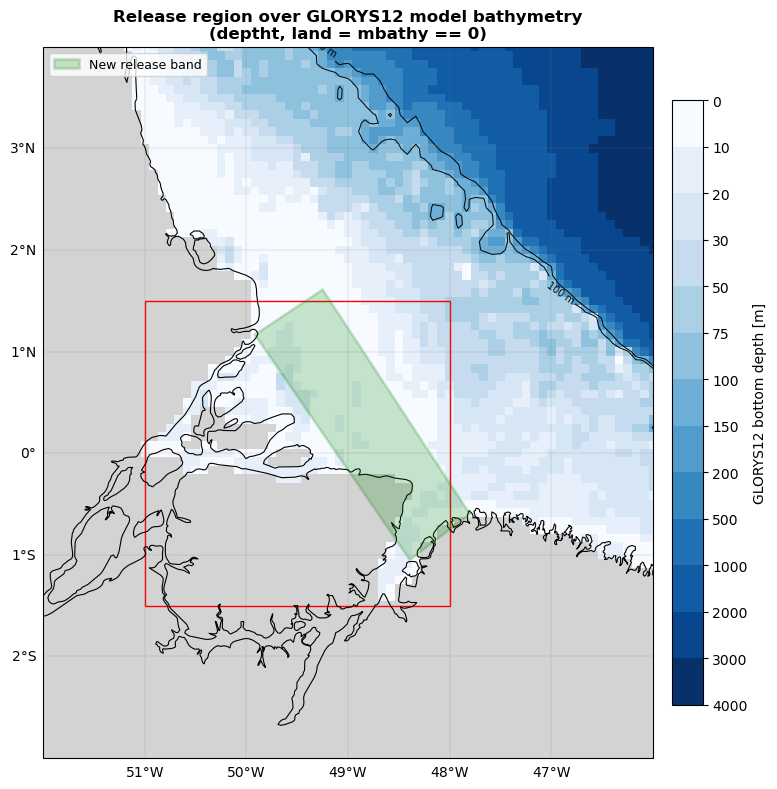

In [41]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

# log-ish depth scale: the shelf detail near the mouth is what matters here
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)

pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(),
                   cmap='Blues', norm=norm, shading='auto', zorder=0)

# model land mask (mbathy == 0), drawn from the model grid itself
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan),
              transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']),
              shading='auto', zorder=1)

# 100 m and 200 m shelf-break isobaths
cs = ax.contour(lon_s, lat_s, bathy, levels=[100, 200], colors='k',
                linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
ax.clabel(cs, fmt='%d m', fontsize=7)

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(),
        facecolor='green', alpha=0.20, edgecolor='green', linewidth=2, zorder=4,
        label='New release band')
# ax.plot(old_lons, old_lats, transform=ccrs.PlateCarree(),
#         color='blue', linewidth=2, linestyle='--', zorder=4, label='Old release line')
# ax.plot(polygon_lons, polygon_lats, transform=ccrs.PlateCarree(),
#         color='red', linewidth=1.2, linestyle=':', zorder=4, label='Coles-style box')

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]')
cb.ax.invert_yaxis()

ax.legend(loc='upper left', fontsize=9)
ax.set_title('Release region over GLORYS12 model bathymetry\n'
             '(deptht, land = mbathy == 0)', fontsize=12, fontweight='bold')
plt.tight_layout()
rect = patches.Rectangle((-51, -1.5), 3, 3, linewidth=1, edgecolor='r', facecolor='none')

# Add the patch to the Axes
ax.add_patch(rect)
# plt.savefig('release_polygon_bathymetry_glorys.png', dpi=200, bbox_inches='tight')
plt.show()

valid: True, area: 1.778 deg^2, 8 vertices


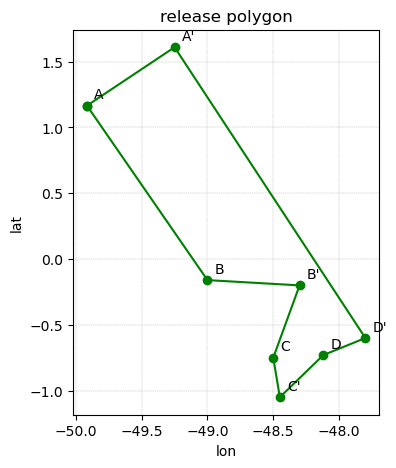

In [37]:
# --- release polygon (editable version) ---
# Define each corner by name. Edit any (lon, lat) below to move that edge.
# Order matters: vertices are connected in sequence, then the ring is closed.
from shapely.geometry import Polygon

vertices = {
    "A":  (-49.916,  1.166),   # Amazon coast  - start of release line
    "B":  (-49, -0.16),
    "B'": (-48.3,-0.2),
    "C":  (-48.5,-0.75),
    "C'": (-48.45,-1.05),
    "D":  (-48.12, -0.73 ),   # Para coast    - line prolonged SE to Para bank
    "D'": (-47.8,   -0.6  ),   # seaward corner off B (pushed NE)
    "A'": (-49.250,  1.610),   # seaward corner off A (0.8 deg perpendicular)
}

# build the closed ring (repeat the first point at the end)
_pts = list(vertices.values())
green_lons = [p[0] for p in _pts] + [_pts[0][0]]
green_lats = [p[1] for p in _pts] + [_pts[0][1]]

# quick validity check + preview
band = Polygon(zip(green_lons[:-1], green_lats[:-1]))
print(f"valid: {band.is_valid}, area: {band.area:.3f} deg^2, "
      f"{len(vertices)} vertices")

# optional: visualize before running the rest
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
plt.plot(green_lons, green_lats, "-o", color="green")
for name, (x, y) in vertices.items():
    plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
plt.xlabel("lon"); plt.ylabel("lat"); plt.title("release polygon")
plt.grid(True, ls="--", lw=0.3); plt.gca().set_aspect("equal"); plt.show()

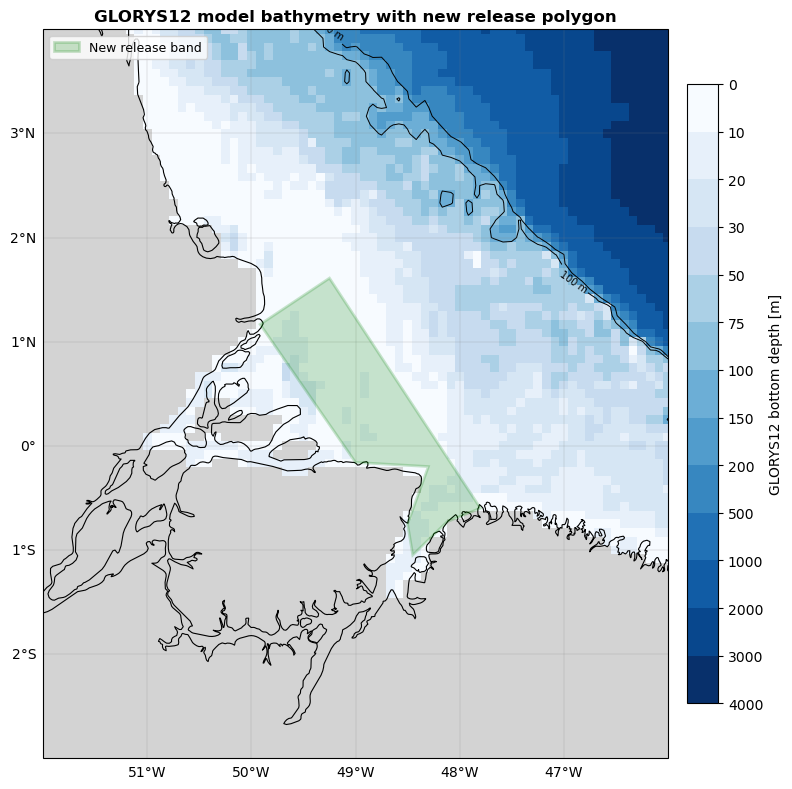

In [38]:
# --- full GLORYS12 bathymetry with the new release polygon on top ---
# Uses bathy / lon_s / lat_s / land_mask from cell [4] and green_lons/green_lats from cell [9].
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)
pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(), cmap='Blues', norm=norm, shading='auto', zorder=0)
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan), transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']), shading='auto', zorder=1)
cs = ax.contour(lon_s, lat_s, bathy, levels=[100, 200], colors='k', linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
ax.clabel(cs, fmt='%d m', fontsize=7)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False; gl.right_labels = False
ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(), facecolor='green', alpha=0.20, edgecolor='green', linewidth=2, zorder=4, label='New release band')
cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85, ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]'); cb.ax.invert_yaxis()
ax.legend(loc='upper left', fontsize=9)
ax.set_title('GLORYS12 model bathymetry with new release polygon', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Supervisor's release region (purple): do U, V, W, T, S all have the same wet cells?

Two sources are checked against the model land mask (`mbathy > 0`):

1. **Raw monthly files** in `variables_c/` (the files the Parcels runs read), first record, top level (k = 0).
   Land is stored as NaN. Surface W is 0 on every wet cell (rigid lid), so W is tested with `isfinite`, not `!= 0`.
2. **Mean zarrs** (`U_m_0_7m`, `V_m_0_7m`, `Sal_m_0_7m`, `temp_m_0_7m`: 0-7 m, 1993-2014). A cell counts as wet if its time mean is finite.
   There is no W mean zarr.

Colours: blue = wet and present, red = wet in `mbathy` but the variable is NaN, grey = land.

In [39]:
# --- purple release region, digitised by hand from the supervisor's sketch (approximate: edit freely) ---
# East side: instead of the sketch's (-47.76,-0.71), (-48.09,-1.09), the line follows D' -> D -> C' of the
# previous release polygon, so the shelf on the east bank of the Para mouth is left out (as in cell 15).
purple_sketch = [(-51.13, -0.04), (-50.88,  0.35), (-50.40,  1.11), (-50.01,  1.31), (-49.53,  1.23),
                 (-49.05,  0.92), (-48.28,  0.39), (-47.90,  0.01), (-47.73, -0.47),
                 (-47.80, -0.60),    # D'  (previous polygon)
                 (-48.12, -0.73),    # D   (previous polygon, on the Para coast -> snapped to nearest wet cell)
                 (-48.45, -1.05),    # C'  (previous polygon)
                 (-48.43, -1.48), (-48.57, -1.53), (-49.00, -1.48), (-49.10, -1.38),
                 (-48.96, -1.00), (-48.62, -0.61), (-48.43, -0.28), (-48.57, -0.18), (-49.05, -0.18),
                 (-50.11, -0.23), (-50.78, -0.13)]


In [40]:
# --- seedable cells: wet in mbathy AND U, V, W, T, S all finite (raw monthly files, first record, k = 0).
#     Wet T cells whose U (east face) or V (north face) is NaN - the red squares in the U/V panels -
#     are treated like land: no vertex, no polygon edge and no seed may sit on them.
dataC = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/'
_seed_files = {'U': ('UVW/U_1993-01c.nc', 'vozocrtx', 'deptht'), 'V': ('UVW/V_1993-01c.nc', 'vomecrty', 'deptht'),
               'W': ('UVW/W_1993-01fc.nc', 'vovecrtz', 'depthw'), 'T': ('tracers/T_1993-01c.nc', 'votemper', 'deptht'),
               'S': ('tracers/S_1993-01c.nc', 'vosaline', 'deptht')}
wetT = mb_s > 0
ok_cell = wetT.copy()
for v, (f, var, dz) in _seed_files.items():
    ok_cell &= np.isfinite(xr.open_dataset(dataC + f)[var].isel({'time_counter': 0, dz: 0}).values[sl])
print(f"window: wet T cells {wetT.sum()}, seedable (all five present) {ok_cell.sum()}, "
      f"wet but U/V NaN {(wetT & ~ok_cell).sum()}")

window: wet T cells 3897, seedable (all five present) 3843, wet but U/V NaN 54


In [41]:
# --- corrected purple line: every vertex that falls on model land (mbathy == 0) is moved to the
#     centre of the nearest SEEDABLE cell (wet, U V W T S present); vertices already on one are left as sketched

def nearest_wet(x, y):
    d2 = (lon_s - x)**2 + (lat_s - y)**2
    j, i = np.unravel_index(d2.argmin(), d2.shape)
    if ok_cell[j, i]:
        return (x, y), False, (j, i)
    j, i = np.unravel_index(np.where(ok_cell, d2, np.inf).argmin(), d2.shape)
    return (round(float(lon_s[j, i]), 3), round(float(lat_s[j, i]), 3)), True, (j, i)

purple = []
for k, (x, y) in enumerate(purple_sketch):
    (nx, ny), moved, ji = nearest_wet(x, y)
    if moved:
        print(f"vertex {k:2d} ({x:7.2f},{y:6.2f}) on land / U-V NaN -> ({nx:7.3f},{ny:6.3f})  depth {bathy[ji]:.1f} m")
    if not purple or (nx, ny) != purple[-1]:            # two vertices snapped to the same cell -> keep one
        purple.append((nx, ny))
if purple[-1] == purple[0]:
    purple.pop()

poly_ok = Polygon(purple).is_valid
print(f"\n{len(purple_sketch)} sketch vertices -> {len(purple)} corrected vertices, polygon valid: {poly_ok}")
print("purple =", [(float(x), float(y)) for x, y in purple])

purple_lons = [p[0] for p in purple] + [purple[0][0]]
purple_lats = [p[1] for p in purple] + [purple[0][1]]
sketch_lons = [p[0] for p in purple_sketch] + [purple_sketch[0][0]]
sketch_lats = [p[1] for p in purple_sketch] + [purple_sketch[0][1]]

in_purple = MplPath(purple).contains_points(
    np.c_[lon_s.ravel(), lat_s.ravel()]).reshape(lon_s.shape)
print(f"T points inside corrected purple: {in_purple.sum()}, wet (mbathy>0): {(in_purple & wetT).sum()}, "
      f"land: {(in_purple & ~wetT).sum()}")

vertex  0 ( -51.13, -0.04) on land / U-V NaN -> (-51.000, 0.000)  depth 15.3 m
vertex  1 ( -50.88,  0.35) on land / U-V NaN -> (-50.750, 0.167)  depth 15.8 m
vertex  2 ( -50.40,  1.11) on land / U-V NaN -> (-50.167, 0.833)  depth 6.4 m
vertex  3 ( -50.01,  1.31) on land / U-V NaN -> (-49.917, 1.333)  depth 6.4 m
vertex 10 ( -48.12, -0.73) on land / U-V NaN -> (-48.083,-0.667)  depth 6.4 m
vertex 12 ( -48.43, -1.48) on land / U-V NaN -> (-48.500,-1.250)  depth 7.6 m
vertex 13 ( -48.57, -1.53) on land / U-V NaN -> (-48.667,-1.417)  depth 18.5 m
vertex 14 ( -49.00, -1.48) on land / U-V NaN -> (-48.667,-1.417)  depth 18.5 m
vertex 15 ( -49.10, -1.38) on land / U-V NaN -> (-48.667,-1.417)  depth 18.5 m
vertex 16 ( -48.96, -1.00) on land / U-V NaN -> (-48.667,-1.167)  depth 17.5 m
vertex 17 ( -48.62, -0.61) on land / U-V NaN -> (-48.500,-0.750)  depth 10.7 m
vertex 21 ( -50.11, -0.23) on land / U-V NaN -> (-50.083,-0.167)  depth 6.4 m
vertex 22 ( -50.78, -0.13) on land / U-V NaN -> (-50.750,

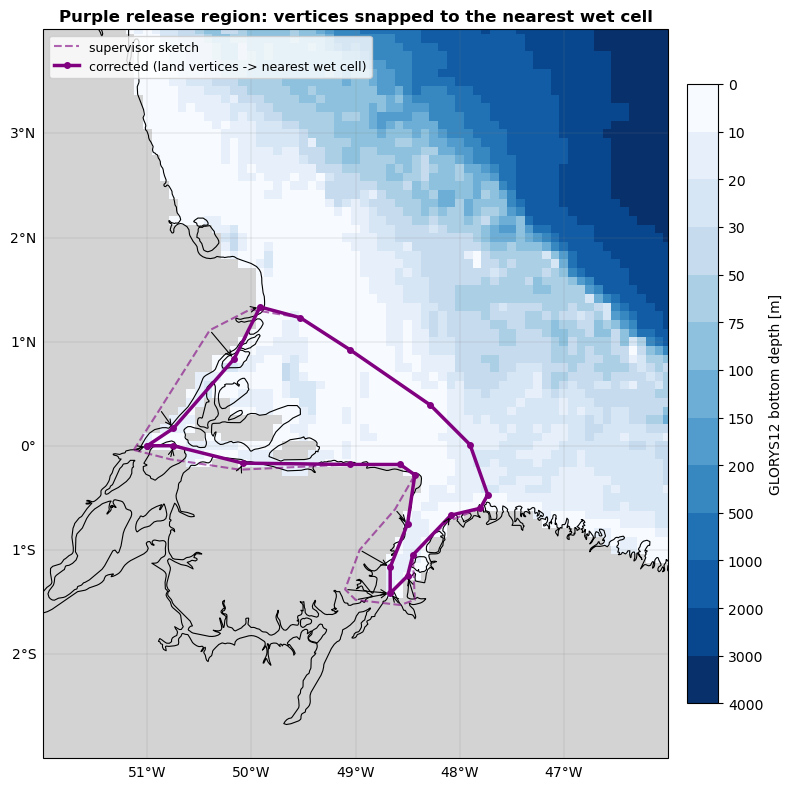

In [42]:
# --- sketch vs corrected purple line over GLORYS12 bathymetry ------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)
pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(), cmap='Blues', norm=norm, shading='auto', zorder=0)
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan), transform=ccrs.PlateCarree(),
              cmap=mcolors.ListedColormap(['lightgray']), shading='auto', zorder=1)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False; gl.right_labels = False
ax.plot(sketch_lons, sketch_lats, color='purple', lw=1.5, ls='--', alpha=0.6, transform=ccrs.PlateCarree(),
        zorder=4, label='supervisor sketch')
ax.plot(purple_lons, purple_lats, '-o', color='purple', lw=2.5, ms=4, transform=ccrs.PlateCarree(),
        zorder=5, label='corrected (land vertices -> nearest wet cell)')
for (x0, y0) in purple_sketch:                       # arrows for the moved vertices
    (x1, y1), moved, _ = nearest_wet(x0, y0)
    if moved:
        ax.annotate('', xy=(x1, y1), xytext=(x0, y0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
                    arrowprops=dict(arrowstyle='->', color='k', lw=0.8), zorder=6)
cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85, ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]'); cb.ax.invert_yaxis()
ax.legend(loc='upper left', fontsize=9)
ax.set_title('Purple release region: vertices snapped to the nearest wet cell', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [43]:
# --- refine edges that cross model LAND (mbathy == 0) ------------------------------------------------------
# For every such edge: shortest path between its two end cells through wet cells (side-by-side steps).
# Step cost = 1 + alpha * distance from the original edge (so the path hugs the wet cells next to land)
#           + a penalty on wet-but-U/V-NaN cells (so the path avoids them wherever the geometry allows).
# Then keep only the turning points needed so no straight segment crosses land; turning points are only
# put on SEEDABLE cells. Repeat until no edge crosses land.
# Note: west of ~50.2W the seedable cells along the coast are only linked through U/V-NaN cells, so some
# edges there must pass over them. That does not matter for seeding: seeds use ok_cell (cell further down).
import heapq

def cell_of(x, y):
    return np.unravel_index(((lon_s - x)**2 + (lat_s - y)**2).argmin(), lon_s.shape)

def land_on_edge(p0, p1, n=400, mask=None):
    mask = wetT if mask is None else mask
    out = []
    for t in np.linspace(0, 1, n):
        ji = cell_of(p0[0] + t * (p1[0] - p0[0]), p0[1] + t * (p1[1] - p0[1]))
        if not mask[ji] and ji not in out:
            out.append(ji)
    return out

def centre(ji):
    return (round(float(lon_s[ji]), 3), round(float(lat_s[ji]), 3))

def path_cells(p0, p1, alpha=20.0, red_penalty=5.0):
    a, b = cell_of(*p0), cell_of(*p1)
    dx, dy = p1[0] - p0[0], p1[1] - p0[1]
    t = np.clip(((lon_s - p0[0]) * dx + (lat_s - p0[1]) * dy) / (dx * dx + dy * dy), 0, 1)
    cost = 1.0 + alpha * np.hypot(lon_s - (p0[0] + t * dx), lat_s - (p0[1] + t * dy)) + red_penalty * (wetT & ~ok_cell)
    ny_, nx_ = wetT.shape
    best = {a: 0.0}; prev = {}; pq = [(0.0, a)]
    while pq:
        d, u = heapq.heappop(pq)
        if u == b:
            break
        if d > best[u]:
            continue
        for dj, di in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            w = (u[0] + dj, u[1] + di)
            if 0 <= w[0] < ny_ and 0 <= w[1] < nx_ and wetT[w]:
                nd = d + cost[w]
                if nd < best.get(w, np.inf):
                    best[w] = nd; prev[w] = u; heapq.heappush(pq, (nd, w))
    if b != a and b not in prev:
        return None
    path = [b]
    while path[-1] != a:
        path.append(prev[path[-1]])
    return path[::-1]

def simplify(p0, p1, cells):
    # greedy line of sight: jump to the farthest SEEDABLE path cell reachable without crossing land
    pts = [p0] + [centre(c) for c in cells[1:-1]] + [p1]
    ok = [True] + [bool(ok_cell[c]) for c in cells[1:-1]] + [True]
    out, i = [p0], 0
    while i < len(pts) - 1:
        j = len(pts) - 1
        while j > i + 1 and (not ok[j] or land_on_edge(pts[i], pts[j])):
            j -= 1
        out.append(pts[j]); i = j
    return out[1:-1]

def refine(poly, max_rounds=20):
    poly = list(poly)
    for rnd in range(max_rounds):
        n = len(poly)
        bad = [k for k in range(n) if land_on_edge(poly[k], poly[(k + 1) % n])]
        if not bad:
            return poly, []
        for k in sorted(bad, reverse=True):            # back to front: indices stay valid while inserting
            p0, p1 = poly[k], poly[(k + 1) % n]
            for alpha in (20.0, 60.0, 5.0):             # retry with another pull if the polygon self-intersects
                cells = path_cells(p0, p1, alpha)
                if cells is None:
                    break
                cand = poly[:k + 1] + simplify(p0, p1, cells) + poly[k + 1:]
                if Polygon(cand).is_valid:
                    print(f"edge {p0} -> {p1}: insert {len(cand) - len(poly)} vertices")
                    poly = cand
                    break
            else:
                print(f"could not fix edge {p0} -> {p1} without self-intersection")
    n = len(poly)
    return poly, [k for k in range(n) if land_on_edge(poly[k], poly[(k + 1) % n])]

purple_snapped = list(purple)
purple, left = refine(purple_snapped)
print(f"\n{len(purple_snapped)} -> {len(purple)} vertices, polygon valid: {Polygon(purple).is_valid}, "
      f"edges still crossing land: {len(left)}")
print(f"vertices on seedable cells: {sum(ok_cell[cell_of(*p)] for p in purple)}/{len(purple)}")
print("purple =", purple)

purple_lons = [p[0] for p in purple] + [purple[0][0]]
purple_lats = [p[1] for p in purple] + [purple[0][1]]
in_purple = MplPath(purple).contains_points(
    np.c_[lon_s.ravel(), lat_s.ravel()]).reshape(lon_s.shape)
print(f"T points inside refined purple: {in_purple.sum()}, wet (mbathy>0): {(in_purple & wetT).sum()}, "
      f"land: {(in_purple & ~wetT).sum()}")


edge (-50.083, -0.167) -> (-50.75, 0.0): insert 1 vertices
edge (-48.5, -0.75) -> (-48.43, -0.28): insert 2 vertices
edge (-48.667, -1.167) -> (-48.5, -0.75): insert 1 vertices
edge (-48.083, -0.667) -> (-48.45, -1.05): insert 1 vertices
edge (-47.8, -0.6) -> (-48.083, -0.667): insert 1 vertices
edge (-50.167, 0.833) -> (-49.917, 1.333): insert 1 vertices

21 -> 28 vertices, polygon valid: True, edges still crossing land: 0
vertices on seedable cells: 28/28
purple = [(-51.0, 0.0), (-50.75, 0.167), (-50.167, 0.833), (-49.917, 1.167), (-49.917, 1.333), (-49.53, 1.23), (-49.05, 0.92), (-48.28, 0.39), (-47.9, 0.01), (-47.73, -0.47), (-47.8, -0.6), (-48.083, -0.583), (-48.083, -0.667), (-48.417, -0.917), (-48.45, -1.05), (-48.5, -1.25), (-48.667, -1.417), (-48.667, -1.167), (-48.5, -0.833), (-48.5, -0.75), (-48.333, -0.417), (-48.333, -0.25), (-48.43, -0.28), (-48.57, -0.18), (-49.05, -0.18), (-50.083, -0.167), (-50.167, -0.083), (-50.75, 0.0)]
T points inside refined purple: 443, wet (mbat

no edge crosses model land


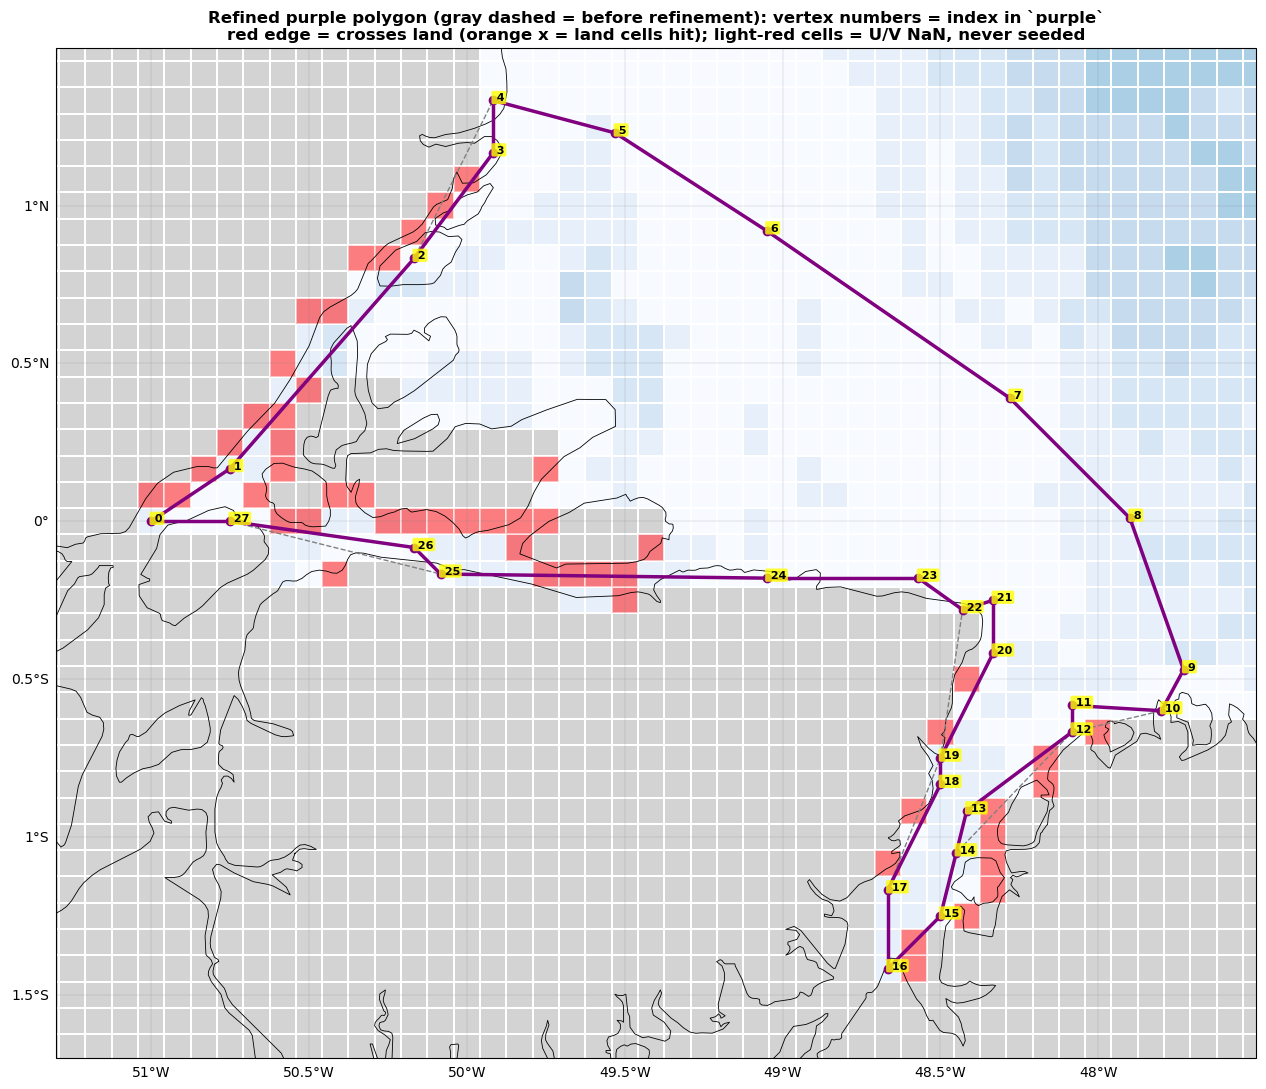

In [44]:
# --- labelled vertices + edges that cross model land (zoom, grid cells outlined) --------------------------
# Vertex k is purple[k]; edge k -> k+1. An edge "crosses land" if any point along it lies in a land T cell.
n_v = len(purple)
bad_edges = {}
for k in range(n_v):
    c = set(land_on_edge(purple[k], purple[(k + 1) % n_v]))
    if c:
        bad_edges[k] = c
        print(f"edge {k:2d} -> {(k + 1) % n_v:2d}  {purple[k]} -> {purple[(k + 1) % n_v]}  crosses {len(c)} land cell(s)")
if not bad_edges:
    print('no edge crosses model land')

ZOOM_P = [-51.3, -47.5, -1.7, 1.5]
fig, ax = plt.subplots(figsize=(13, 11), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(ZOOM_P, crs=ccrs.PlateCarree())
ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(), cmap='Blues', norm=norm,
              shading='nearest', edgecolors='w', linewidth=0.2, zorder=0)
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan), transform=ccrs.PlateCarree(),
              cmap=mcolors.ListedColormap(['lightgray']), shading='nearest', edgecolors='w', linewidth=0.2, zorder=1)
ax.pcolormesh(lon_s, lat_s, np.where(wetT & ~ok_cell, 1.0, np.nan), transform=ccrs.PlateCarree(),   # U/V NaN
              cmap=mcolors.ListedColormap(['red']), alpha=0.5, shading='nearest', edgecolors='w', linewidth=0.2, zorder=1)
for c in bad_edges.values():                         # land cells hit by an edge
    for j, i in c:
        ax.plot(lon_s[j, i], lat_s[j, i], 'x', color='orange', ms=6, mew=1.5, transform=ccrs.PlateCarree(), zorder=6)
ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=3)
ax.plot([p[0] for p in purple_snapped] + [purple_snapped[0][0]], [p[1] for p in purple_snapped] + [purple_snapped[0][1]],
        '--', color='gray', lw=1, transform=ccrs.PlateCarree(), zorder=4)   # before refinement
for k in range(n_v):
    p0, p1 = purple[k], purple[(k + 1) % n_v]
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color='red' if k in bad_edges else 'purple', lw=2.5,
            transform=ccrs.PlateCarree(), zorder=5)
for k, (x, y) in enumerate(purple):
    ax.plot(x, y, 'o', color='purple', ms=6, transform=ccrs.PlateCarree(), zorder=7)
    ax.text(x, y, f' {k}', fontsize=8, fontweight='bold', color='k', transform=ccrs.PlateCarree(), zorder=8,
            bbox=dict(boxstyle='round,pad=0.15', fc='yellow', ec='none', alpha=0.8))
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.set_title('Refined purple polygon (gray dashed = before refinement): vertex numbers = index in `purple`\n'
             'red edge = crosses land (orange x = land cells hit); light-red cells = U/V NaN, never seeded', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

island groups inside the polygon: 1  (65 dry cells, 23 of them wet-but-U/V-NaN)
seed cells: 377   of which around islands (ring): 36
excluded inside polygon: land 42, wet but U/V NaN 24


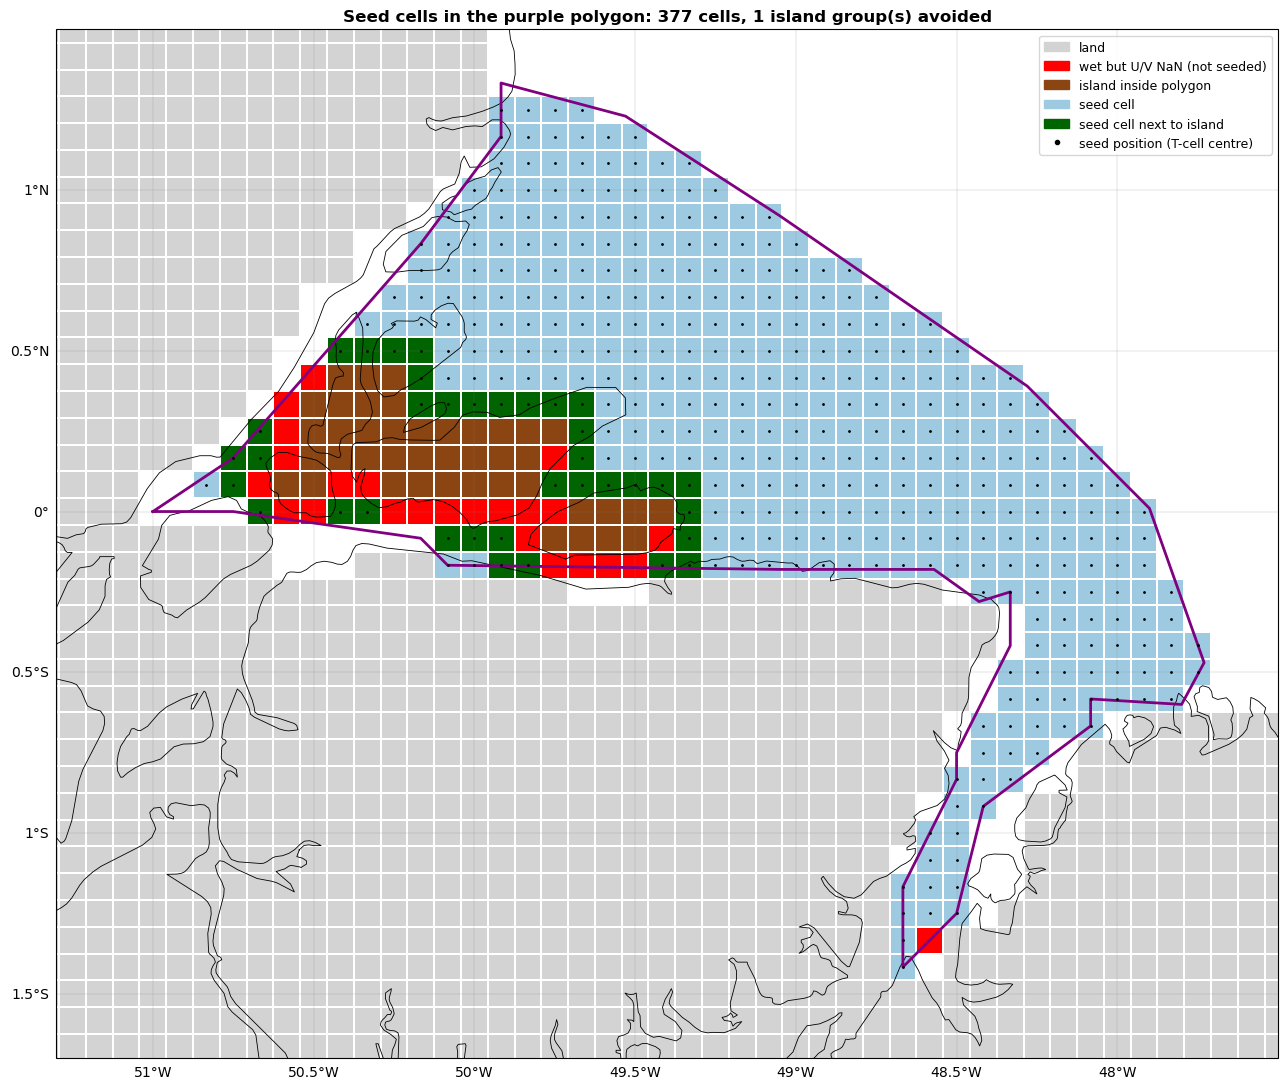

In [45]:
# --- seed cells inside the purple polygon ---------------------------------------------------------------
# Seeds go on the centres of SEEDABLE cells (ok_cell) inside the polygon. Islands inside the polygon (land
# + the U/V-NaN cells around it) are never seeded; they are surrounded by their ring of first seedable
# neighbour cells (8-neighbourhood): where the cell next to the land is a red U/V-NaN cell, the ring is the
# next cell out.
from scipy import ndimage

# non-seedable cells inside the polygon (land + U/V-NaN); an island is a connected piece of them that
# contains land. U/V-NaN cells on their own (next to the polygon edge) are just excluded.
nonseed = in_purple & ~ok_cell
lab, nlab = ndimage.label(nonseed, structure=np.ones((3, 3)))
island_ids = [l for l in range(1, nlab + 1) if ((lab == l) & ~wetT).any()]
islands = np.isin(lab, island_ids)

ring = ndimage.binary_dilation(islands, structure=np.ones((3, 3))) & ok_cell & in_purple
seed_mask = in_purple & ok_cell

print(f"island groups inside the polygon: {len(island_ids)}  ({islands.sum()} dry cells, "
      f"{(islands & wetT).sum()} of them wet-but-U/V-NaN)")
print(f"seed cells: {seed_mask.sum()}   of which around islands (ring): {ring.sum()}")
print(f"excluded inside polygon: land {(in_purple & ~wetT).sum()}, wet but U/V NaN {(in_purple & wetT & ~ok_cell).sum()}")

seed_j, seed_i = np.where(seed_mask)
seed_lon, seed_lat = lon_s[seed_j, seed_i], lat_s[seed_j, seed_i]   # release positions (T-cell centres)

# --- plot ---------------------------------------------------------------------------------------------
cat = np.full(lon_s.shape, np.nan)
cat[~wetT] = 0                              # land
cat[wetT & ~ok_cell] = 1                    # wet but U/V NaN (not seedable)
cat[islands & ~wetT] = 2                    # island land inside the polygon
cat[seed_mask] = 3                          # seed
cat[ring] = 4                               # seed, ring around an island
cmap_seed = mcolors.ListedColormap(['lightgray', 'red', 'saddlebrown', '#9ecae1', 'darkgreen'])

fig, ax = plt.subplots(figsize=(13, 11), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent([-51.3, -47.5, -1.7, 1.5], crs=ccrs.PlateCarree())
ax.pcolormesh(lon_s, lat_s, np.where(in_purple | ~wetT, cat, np.nan), transform=ccrs.PlateCarree(),
              cmap=cmap_seed, vmin=-0.5, vmax=4.5, shading='nearest', edgecolors='w', linewidth=0.2, zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=3)
ax.plot(purple_lons, purple_lats, color='purple', lw=2, transform=ccrs.PlateCarree(), zorder=4)
ax.plot(seed_lon, seed_lat, '.', color='k', ms=2, transform=ccrs.PlateCarree(), zorder=5)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap_seed.colors] + [plt.Line2D([], [], ls='', marker='.', color='k')],
          ['land', 'wet but U/V NaN (not seeded)', 'island inside polygon', 'seed cell', 'seed cell next to island',
           'seed position (T-cell centre)'], loc='upper right', fontsize=9)
ax.set_title(f'Seed cells in the purple polygon: {seed_mask.sum()} cells, {len(island_ids)} island group(s) avoided',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [46]:
# --- wet masks: raw monthly files (variables_c, first record, k = 0) --------------------------------
dataC = '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/'
raw_files = {'U': ('UVW/U_1993-01c.nc',      'vozocrtx', 'deptht'),
             'V': ('UVW/V_1993-01c.nc',      'vomecrty', 'deptht'),
             'W': ('UVW/W_1993-01fc.nc',     'vovecrtz', 'depthw'),
             'T': ('tracers/T_1993-01c.nc',  'votemper', 'deptht'),
             'S': ('tracers/S_1993-01c.nc',  'vosaline', 'deptht')}
wet_raw = {}
for v, (f, var, dz) in raw_files.items():
    d = xr.open_dataset(dataC + f)[var].isel({'time_counter': 0, dz: 0}).values
    wet_raw[v] = np.isfinite(d[sl])

# --- wet masks: mean zarrs (0-7 m, 1993-2014 monthly means) -----------------------------------------
# same 499 x 1260 grid as the mesh (inside EXTENT the zarr lat/lon equal gphit/glamt exactly)
wet_mean = {
    'U': np.isfinite(xr.open_zarr('U_m_0_7m.zarr').U.mean('time_counter').values[sl]),
    'V': np.isfinite(xr.open_zarr('V_m_0_7m.zarr').V.mean('time_counter').values[sl]),
    'W': None,                                                     # no W mean available
    'T': np.isfinite(xr.open_zarr('temp_m_0_7m.zarr').temp.mean('time').values[sl]),
    'S': np.isfinite(xr.open_zarr('Sal_m_0_7m.zarr').sal.mean('time').values[sl]),
}

# --- summary table inside the purple polygon ------------------------------------------------------
print(f"{'':6s}{'var':4s}{'wet in purple':>15s}{'missing (wet T, var NaN)':>27s}{'finite on land':>16s}")
for name, masks in [('raw', wet_raw), ('mean', wet_mean)]:
    for v, m in masks.items():
        if m is None:
            print(f"{name:6s}{v:4s}{'n/a':>15s}")
            continue
        print(f"{name:6s}{v:4s}{(in_purple & m).sum():15d}{(in_purple & wetT & ~m).sum():27d}"
              f"{(in_purple & ~wetT & m).sum():16d}")
all5 = wet_raw['U'] & wet_raw['V'] & wet_raw['W'] & wet_raw['T'] & wet_raw['S']
print(f"\nwet T cells in purple: {(in_purple & wetT).sum()},  all five present: {(in_purple & all5).sum()}, "
      f" U and/or V missing: {(in_purple & wetT & ~all5).sum()}")
print('raw vs mean masks identical?  U:', (wet_raw['U'] == wet_mean['U']).all(),
      ' V:', (wet_raw['V'] == wet_mean['V']).all(), ' T:', (wet_raw['T'] == wet_mean['T']).all(),
      ' S:', (wet_raw['S'] == wet_mean['S']).all())

      var   wet in purple   missing (wet T, var NaN)  finite on land
raw   U               392                          9               0
raw   V               385                         16               0
raw   W               401                          0               0
raw   T               401                          0               0
raw   S               401                          0               0
mean  U               392                          9               0
mean  V               385                         16               0
mean  W               n/a
mean  T               401                          0               0
mean  S               401                          0               0

wet T cells in purple: 401,  all five present: 377,  U and/or V missing: 24
raw vs mean masks identical?  U: True  V: True  T: True  S: True


In [47]:
# --- why are U/V missing? NEMO C-grid: U(j,i) sits on the EAST face of T(j,i), V(j,i) on the NORTH face.
# umask = tmask(i) * tmask(i+1), vmask = tmask(j) * tmask(j+1)  ->  a face that touches land is NaN.
land_east  = wetT & ~np.roll(wetT, -1, axis=1)
land_north = wetT & ~np.roll(wetT, -1, axis=0)
land_east[:, -1] = land_north[-1, :] = False      # np.roll wraps the window edges around: drop them
for v, face in [('U', land_east), ('V', land_north)]:
    miss = wetT & ~wet_raw[v]
    print(f"{v}: missing on wet T cells = {miss.sum()},  of which the face touches land = {(miss & face).sum()},  "
          f"land-touching faces that are NOT NaN = {(face & wet_raw[v]).sum()}")

U: missing on wet T cells = 21,  of which the face touches land = 21,  land-touching faces that are NOT NaN = 0
V: missing on wet T cells = 34,  of which the face touches land = 34,  land-touching faces that are NOT NaN = 0


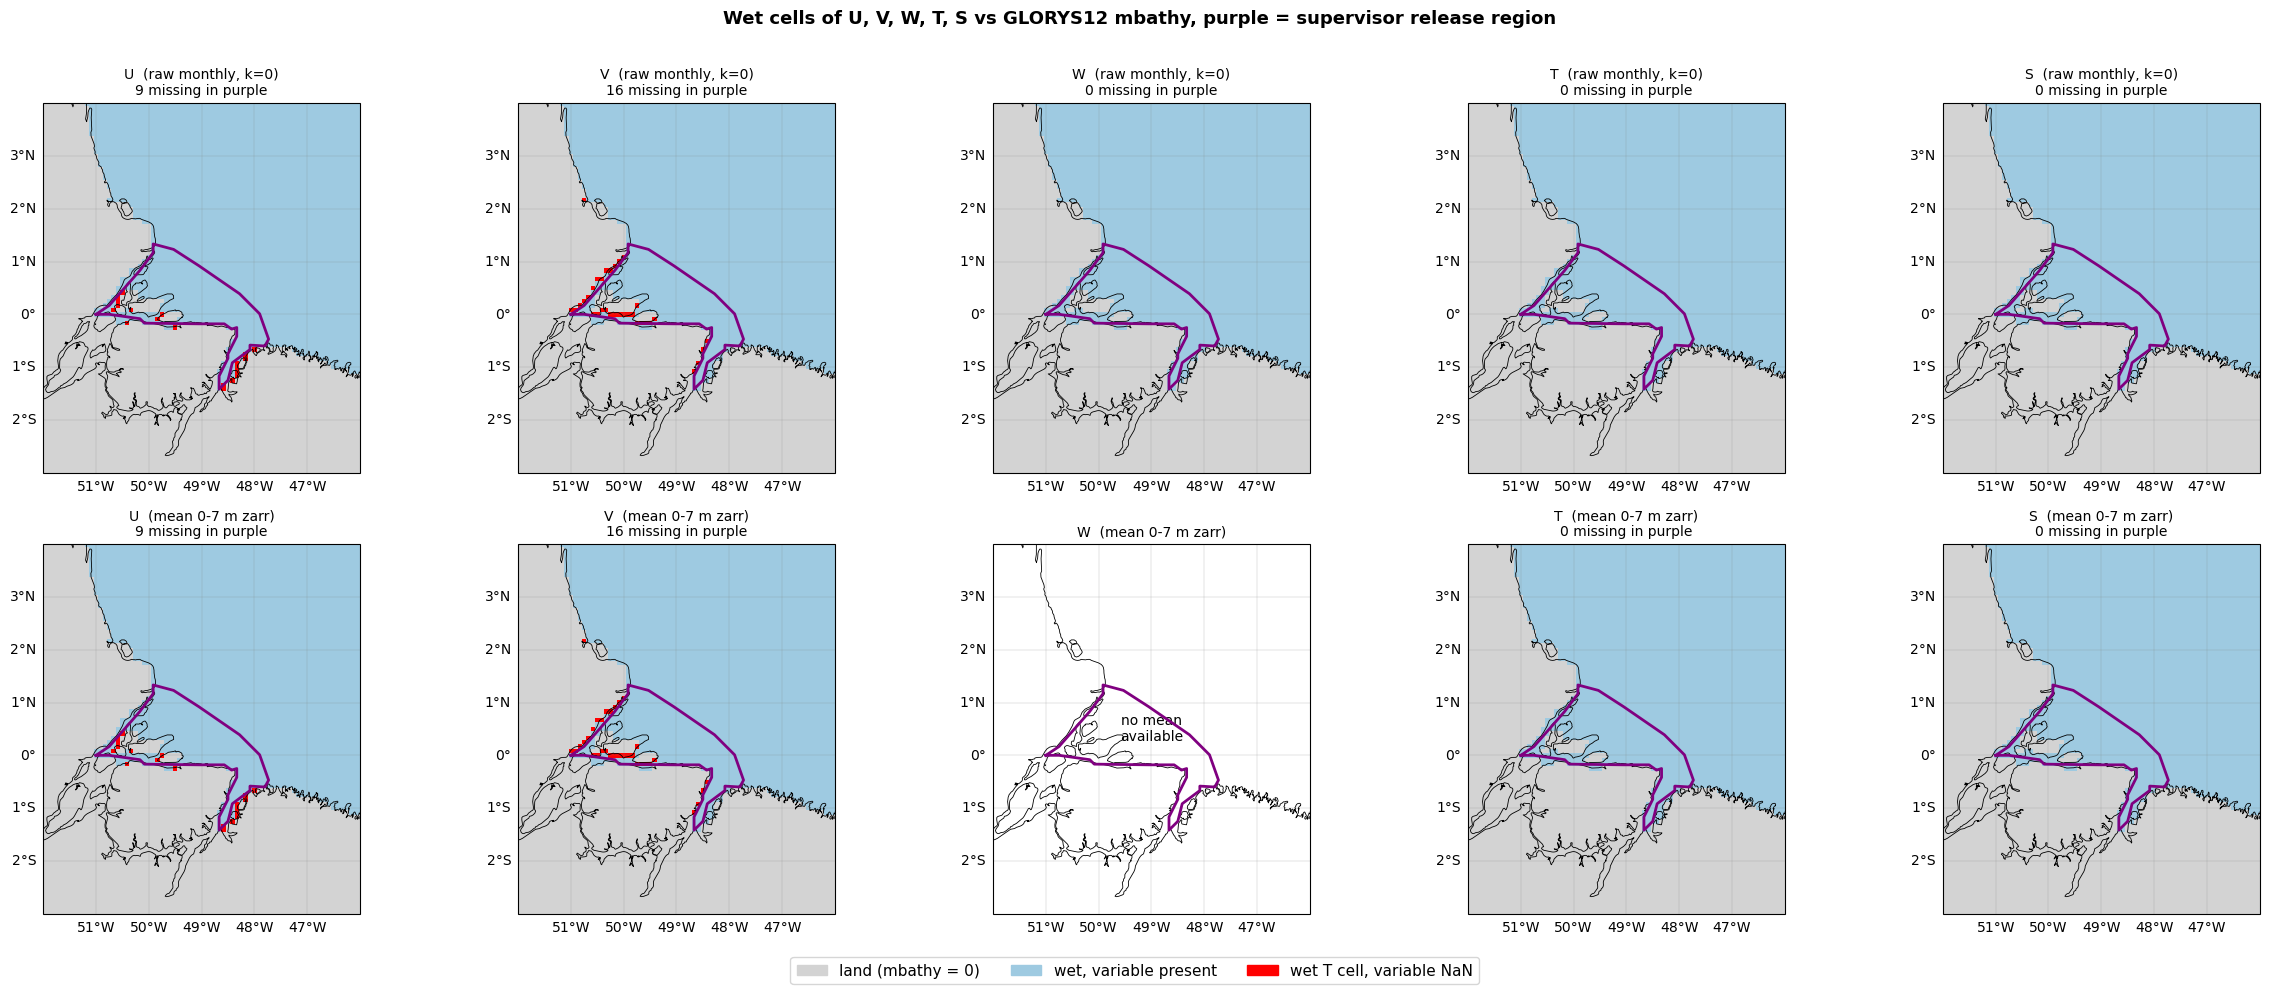

In [48]:
# --- panels: wet masks of U V W T S side by side (top: raw monthly files, bottom: mean zarrs) ---------
cat_cmap = mcolors.ListedColormap(['lightgray', '#9ecae1', 'red'])   # 0 land, 1 wet+present, 2 wet but NaN

def wet_category(m):
    c = np.zeros(wetT.shape)
    c[wetT & m] = 1
    c[wetT & ~m] = 2
    c[~wetT & m] = 1          # would show a variable that is finite on land (does not happen here)
    return c

def mask_panel(ax, m, title, extent, edges=False):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    if m is None:
        ax.text(0.5, 0.5, 'no mean\navailable', transform=ax.transAxes, ha='center', va='center')
    else:
        ax.pcolormesh(lon_s, lat_s, wet_category(m), transform=ccrs.PlateCarree(), cmap=cat_cmap,
                      vmin=-0.5, vmax=2.5, shading='nearest',
                      edgecolors='w' if edges else 'face', linewidth=0.2 if edges else 0)
        n_miss = (in_purple & wetT & ~m).sum()
        title += f'\n{n_miss} missing in purple'
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=3)
    ax.plot(purple_lons, purple_lats, color='purple', lw=2, transform=ccrs.PlateCarree(), zorder=4)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
    gl.top_labels = gl.right_labels = False
    ax.set_title(title, fontsize=10)

order = ['U', 'V', 'W', 'T', 'S']
fig, axes = plt.subplots(2, 5, figsize=(24, 10), subplot_kw=dict(projection=ccrs.PlateCarree()))
for k, v in enumerate(order):
    mask_panel(axes[0, k], wet_raw[v],  f'{v}  (raw monthly, k=0)', EXTENT)
    mask_panel(axes[1, k], wet_mean[v], f'{v}  (mean 0-7 m zarr)',  EXTENT)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cat_cmap.colors]
fig.legend(handles, ['land (mbathy = 0)', 'wet, variable present', 'wet T cell, variable NaN'],
           loc='lower center', ncol=3, fontsize=11)
fig.suptitle('Wet cells of U, V, W, T, S vs GLORYS12 mbathy, purple = supervisor release region',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

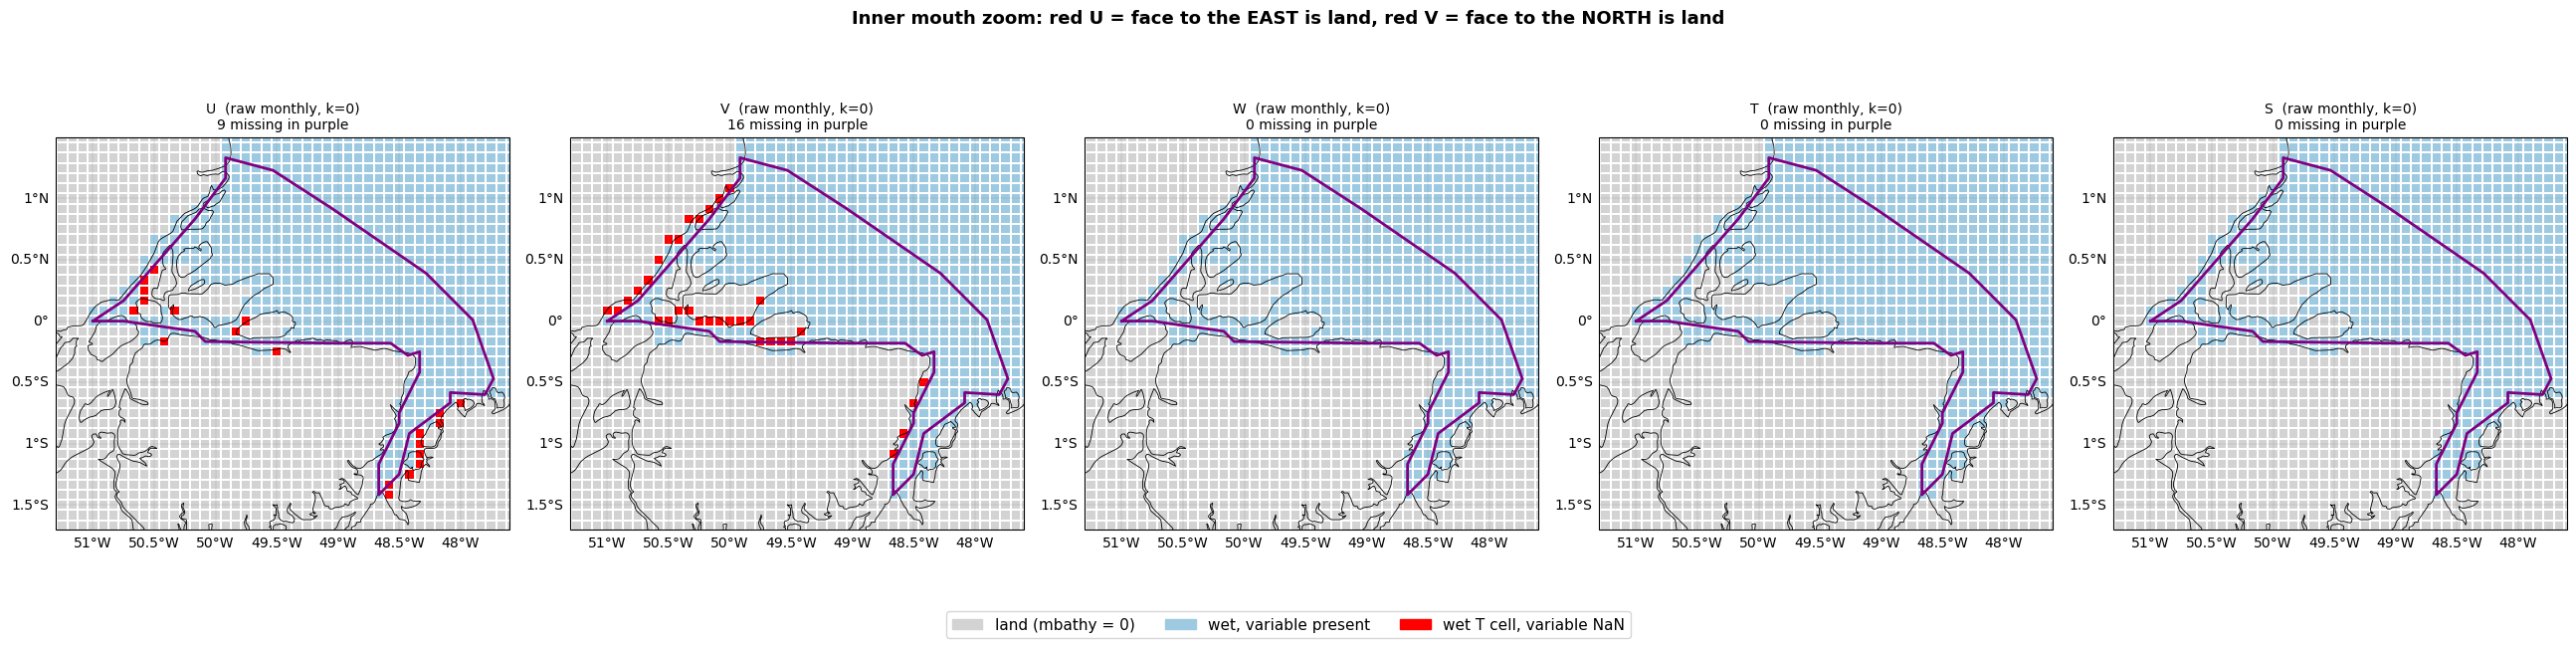

In [49]:
# --- zoom on the inner Amazon / Para mouth, individual cells outlined (raw monthly files) ------------
ZOOM = [-51.3, -47.6, -1.7, 1.5]
fig, axes = plt.subplots(1, 5, figsize=(26, 6.5), subplot_kw=dict(projection=ccrs.PlateCarree()))
for k, v in enumerate(order):
    mask_panel(axes[k], wet_raw[v], f'{v}  (raw monthly, k=0)', ZOOM, edges=True)
fig.legend(handles, ['land (mbathy = 0)', 'wet, variable present', 'wet T cell, variable NaN'],
           loc='lower center', ncol=3, fontsize=11)
fig.suptitle('Inner mouth zoom: red U = face to the EAST is land, red V = face to the NORTH is land',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()